# Tier 2: LangGraph Orchestrator (Finalized)

Finalized sequential-gating orchestrator built with LangGraph, using the currently designated Week-3 Tier-1 score files and the finalized Fusion weighting strategy.

**Architecture (sequential gating — preserved):**
```
START
  ↓
compute_risk_score
  ↓
check_high_confidence  (HTTP-only)
  ├── http_score > HC_THRESHOLD → generate_llm_rationale → END (escalate)
  ↓ (HC not triggered)
check_correlation
  ├── correlation_score > CORRELATION_THRESHOLD → generate_llm_rationale → END (escalate)
  ↓ (neither triggered)
NORMAL → END
```

The correlation gate is evaluated **only when** the high-confidence gate has not triggered (strict sequential gating). There is **no "Both" decision category** — each row is exactly one of: `high_confidence`, `correlation`, `normal`.

**Tier-1 inputs (designated Week-3 files):**
- `week3/tier1_validation_scores.csv` — used ONLY for threshold calibration (Phase 1)
- `week3/tier1_test_scores.csv` — untouched until the final evaluation (Phase 2)

**Provenance (finalized Tier-1 models):**
```
HTTP        = finalized 6:1 MLP
File/Device = finalized 4:1 MLP
Email       = finalized 4:1 MLP
Logon       = finalized 4:1 MLP
```

**Finalized correlation weights (FIXED, from the Fusion Agent selection):** HTTP 0.60, File/Device 0.20, Logon 0.10, Email 0.10.

## Phase 1 — Validation Calibration

Load **validation only**. No test data is touched in this phase.

In [1]:
import pandas as pd
import numpy as np
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from sklearn.metrics import (recall_score, precision_score, f1_score, accuracy_score,
                             roc_auc_score, confusion_matrix, roc_curve)
from pathlib import Path
from IPython.display import display, Markdown
import time
import warnings
warnings.filterwarnings('ignore')

# Resolve paths (portability convention)
_curr = Path.cwd()
while not (_curr / 'pyproject.toml').exists() and _curr != _curr.parent:
    _curr = _curr.parent
PROJECT_ROOT = _curr
WEEK3_DIR = PROJECT_ROOT / 'week3'

# ============ PHASE 1: VALIDATION ONLY ============
validation_path = WEEK3_DIR / 'tier1_validation_scores.csv'
test_path = WEEK3_DIR / 'tier1_test_scores.csv'

# Load VALIDATION only for threshold selection. Test is NOT read in Phase 1.
df_val = pd.read_csv(validation_path)

# --- Schema / integrity checks on validation ---
required = {'user', 'week', 'day', 'label'}
scores = ['logon_score', 'email_score', 'file_device_score', 'http_score']
missing = required - set(df_val.columns)
assert not missing, f'missing required columns: {missing}'
for sc in scores:
    assert sc in df_val.columns, f'missing score column {sc}'
dup = int(df_val.duplicated(subset=['user', 'week', 'day']).sum())
assert dup == 0, f'{dup} duplicate (user, week, day) in validation'
assert df_val['label'].isin([0, 1]).all()
sc_arr = df_val[scores].values
assert (sc_arr >= 0).all() and (sc_arr <= 1).all(), 'scores out of [0,1]'

print('Tier-1 validation score file:', validation_path)
print(f'Validation rows: {len(df_val)} | users: {df_val["user"].nunique()} | positives: {int(df_val["label"].sum())}')
print('Provenance: HTTP=6:1 MLP, File/Device=4:1 MLP, Email=4:1 MLP, Logon=4:1 MLP (finalized).')
print('No Tier-1 model retrained. Test file NOT loaded in Phase 1.')

y_val = df_val['label'].values

# Finalized correlation weights (FIXED — no weight selection in this notebook)
W_HTTP, W_FILE, W_LOGON, W_EMAIL = 0.60, 0.20, 0.10, 0.10
def correlation_score(d):
    return (d['http_score'] * W_HTTP +
            d['file_device_score'] * W_FILE +
            d['logon_score'] * W_LOGON +
            d['email_score'] * W_EMAIL)

df_val['correlation_score'] = correlation_score(df_val)

Tier-1 validation score file: C:\insider_threat_detection_project2\week3\tier1_validation_scores.csv
Validation rows: 61076 | users: 200 | positives: 191
Provenance: HTTP=6:1 MLP, File/Device=4:1 MLP, Email=4:1 MLP, Logon=4:1 MLP (finalized).
No Tier-1 model retrained. Test file NOT loaded in Phase 1.


## 1A. HC threshold selection (validation only, HTTP-only gate)

In [2]:
# HC gate policy is FIXED to HTTP-only.
# Methodology (preserved from the original orchestrator): sweep thresholds on the
# VALIDATION set, maximize Youden's J = Recall - FPR. Test data is not involved.
hc_candidates = np.arange(0.50, 0.96, 0.05)
hc_rows = []
for t in hc_candidates:
    preds = (df_val['http_score'] > t).astype(int)
    rec = recall_score(y_val, preds, zero_division=0)
    tn0, fp0, fn0, tp0 = confusion_matrix(y_val, preds).ravel()
    fpr0 = fp0 / (fp0 + tn0) if (fp0 + tn0) > 0 else 0
    prec = precision_score(y_val, preds, zero_division=0)
    f1 = f1_score(y_val, preds, zero_division=0)
    j = rec - fpr0
    hc_rows.append({'HC Threshold': t, 'Recall': rec, 'FPR': fpr0,
                    'Precision': prec, 'F1': f1, 'Youden J': j})

hc_table = pd.DataFrame(hc_rows)
display(Markdown('### HC threshold sweep (VALIDATION only)'))
display(hc_table.round(4))

best_hc = hc_table.loc[hc_table['Youden J'].idxmax()]
HC_THRESHOLD = float(best_hc['HC Threshold'])
print(f'\n[SELECTED ON VALIDATION] HC_THRESHOLD = {HC_THRESHOLD:.2f} '
      f'(max Youden J = {best_hc["Youden J"]:.4f}, Recall={best_hc["Recall"]:.4f}, FPR={best_hc["FPR"]:.4f})')

### HC threshold sweep (VALIDATION only)

,HC Threshold,Recall,FPR,Precision,F1,Youden J
0,0.50,0.9372,0.0062,0.3231,0.4805,0.9310
1,0.55,0.9319,0.0059,0.3309,0.4883,0.9260
2,0.60,0.9267,0.0057,0.3378,0.4951,0.9210
3,0.65,0.9215,0.0055,0.3458,0.5029,0.9160
4,0.70,0.9215,0.0052,0.3577,0.5154,0.9163
5,0.75,0.9110,0.0049,0.3686,0.5249,0.9061
6,0.80,0.9110,0.0046,0.3807,0.5370,0.9063
7,0.85,0.9058,0.0043,0.3995,0.5545,0.9015
8,0.90,0.8953,0.0038,0.4222,0.5738,0.8914
9,0.95,0.8534,0.0032,0.4566,0.5949,0.8502



[SELECTED ON VALIDATION] HC_THRESHOLD = 0.50 (max Youden J = 0.9310, Recall=0.9372, FPR=0.0062)


## 1B. Correlation threshold selection (validation only, fixed 60/20/10/10 weights)

In [3]:
# Correlation gate uses the FINAL 60/20/10/10 weights (no weight selection here).
# Methodology (preserved): sweep thresholds on VALIDATION, maximize Youden's J.
corr_candidates = np.arange(0.10, 0.91, 0.01)
corr_rows = []
for t in corr_candidates:
    preds = (df_val['correlation_score'] > t).astype(int)
    rec = recall_score(y_val, preds, zero_division=0)
    tn0, fp0, fn0, tp0 = confusion_matrix(y_val, preds).ravel()
    fpr0 = fp0 / (fp0 + tn0) if (fp0 + tn0) > 0 else 0
    prec = precision_score(y_val, preds, zero_division=0)
    f1 = f1_score(y_val, preds, zero_division=0)
    j = rec - fpr0
    corr_rows.append({'Corr Threshold': t, 'Recall': rec, 'FPR': fpr0,
                      'Precision': prec, 'F1': f1, 'Youden J': j})

corr_table = pd.DataFrame(corr_rows)
display(Markdown('### Correlation threshold sweep (VALIDATION only)'))
display(corr_table.round(4))

best_corr = corr_table.loc[corr_table['Youden J'].idxmax()]
CORRELATION_THRESHOLD = float(best_corr['Corr Threshold'])
print(f'\n[SELECTED ON VALIDATION] CORRELATION_THRESHOLD = {CORRELATION_THRESHOLD:.2f} '
      f'(max Youden J = {best_corr["Youden J"]:.4f}, Recall={best_corr["Recall"]:.4f}, FPR={best_corr["FPR"]:.4f})')

### Correlation threshold sweep (VALIDATION only)

,Corr Threshold,Recall,FPR,Precision,F1,Youden J
0,0.10,0.9948,0.1375,0.0222,0.0434,0.8572
1,0.11,0.9895,0.1197,0.0253,0.0493,0.8698
2,0.12,0.9843,0.1051,0.0285,0.0555,0.8792
3,0.13,0.9843,0.0916,0.0326,0.0631,0.8927
4,0.14,0.9843,0.0791,0.0376,0.0724,0.9052
...,...,...,...,...,...,...
76,0.86,0.0576,0.0001,0.7333,0.1068,0.0575
77,0.87,0.0471,0.0001,0.6923,0.0882,0.0471
78,0.88,0.0314,0.0000,0.7500,0.0603,0.0314
79,0.89,0.0209,0.0000,0.8000,0.0408,0.0209



[SELECTED ON VALIDATION] CORRELATION_THRESHOLD = 0.22 (max Youden J = 0.9712, Recall=0.9843, FPR=0.0131)


## 1C. FREEZE both thresholds (selected on validation, before any test access)

In [4]:
# Both thresholds are now FROZEN. They were selected on the validation set only.
print('=' * 55)
print('  FROZEN THRESHOLDS (SELECTED ON VALIDATION)')
print('=' * 55)
print(f'  HC_THRESHOLD          = {HC_THRESHOLD:.2f}   (HTTP-only gate)')
print(f'  CORRELATION_THRESHOLD = {CORRELATION_THRESHOLD:.2f}   (60/20/10/10 weighted risk)')
print(f'  Correlation weights:  HTTP={W_HTTP}, File/Device={W_FILE}, Logon={W_LOGON}, Email={W_EMAIL}')
print('  These values will NOT be changed by any test result.')
print('=' * 55)

# Sequential gate decision (single source of truth for both the graph and analysis)
def sequential_decision(http_score, corr_score):
    """Return (escalate, gate): strictly sequential, no 'Both' category."""
    if http_score > HC_THRESHOLD:
        return True, 'high_confidence'
    if corr_score > CORRELATION_THRESHOLD:
        return True, 'correlation'
    return False, 'normal'

  FROZEN THRESHOLDS (SELECTED ON VALIDATION)
  HC_THRESHOLD          = 0.50   (HTTP-only gate)
  CORRELATION_THRESHOLD = 0.22   (60/20/10/10 weighted risk)
  Correlation weights:  HTTP=0.6, File/Device=0.2, Logon=0.1, Email=0.1
  These values will NOT be changed by any test result.


## 2. Define State & Graph Nodes (architecture preserved)

In [5]:
class FusionState(TypedDict):
    """State passed through the LangGraph orchestrator."""
    logon_score: float
    email_score: float
    file_device_score: float
    http_score: float
    user: float
    day: float
    risk_score: float
    escalate: bool
    rationale: str
    gate_triggered: str

def compute_risk_score(state: FusionState) -> dict:
    """Finalized weighted risk score (60/20/10/10)."""
    risk = (state['http_score'] * W_HTTP +
            state['file_device_score'] * W_FILE +
            state['logon_score'] * W_LOGON +
            state['email_score'] * W_EMAIL)
    return {'risk_score': risk}

def check_high_confidence(state: FusionState) -> dict:
    """Gate 1 (HTTP-only): escalate if http_score > HC_THRESHOLD."""
    if state['http_score'] > HC_THRESHOLD:
        rationale = (
            f'HIGH-CONFIDENCE ESCALATION: HTTP anomaly score ({state["http_score"]:.3f}) '
            f'exceeds threshold ({HC_THRESHOLD}). Strong single-channel behavioral deviation '
            f'consistent with insider threat activity (e.g., bulk data exfiltration via http).'
        )
        return {'escalate': True, 'rationale': rationale, 'gate_triggered': 'high_confidence'}
    return {'escalate': False, 'rationale': '', 'gate_triggered': ''}

def check_correlation(state: FusionState) -> dict:
    """Gate 2: escalate if finalized weighted risk exceeds CORRELATION_THRESHOLD."""
    total = (state['http_score'] * W_HTTP +
             state['file_device_score'] * W_FILE +
             state['logon_score'] * W_LOGON +
             state['email_score'] * W_EMAIL)
    if total > CORRELATION_THRESHOLD:
        contributions = []
        for name, score in [('HTTP', state['http_score']), ('File', state['file_device_score']),
                            ('Logon', state['logon_score']), ('Email', state['email_score'])]:
            if score > 0.1:
                contributions.append(f'{name}={score:.3f}')
        rationale = (
            f'CORRELATION ESCALATION: Weighted anomaly signal (weighted_sum={total:.3f}) exceeds '
            f'threshold ({CORRELATION_THRESHOLD:.2f}). Multiple channels show coordinated '
            f'deviation: [{", ".join(contributions)}]. This pattern suggests a multi-stage '
            f'insider operation.'
        )
        return {'escalate': True, 'rationale': rationale, 'gate_triggered': 'correlation'}
    return {'escalate': False,
            'rationale': f'NORMAL: Weighted combined signal ({total:.3f}) below threshold.',
            'gate_triggered': 'normal'}

def generate_llm_rationale(state: FusionState) -> dict:
    """Tier-3 LLM Node: template-based rationale for escalated cases (preserved)."""
    if not state['escalate']:
        return {'rationale': state['rationale']}
    scores = {
        'HTTP': state['http_score'],
        'File/Device': state['file_device_score'],
        'Logon': state['logon_score'],
        'Email': state['email_score'],
    }
    sorted_channels = sorted(scores.items(), key=lambda x: x[1], reverse=True)
    primary, secondary = sorted_channels[0], sorted_channels[1]
    detailed = (
        f'[TIER-3 ANALYSIS] User {int(state["user"])} on day {int(state["day"])}: '
        f'Primary anomaly in {primary[0]} (score={primary[1]:.3f}), '
        f'secondary signal in {secondary[0]} (score={secondary[1]:.3f}). '
        f'Risk score: {state["risk_score"]:.3f}. '
        f'Gate: {state["gate_triggered"]}. '
        f'Recommended action: Flag for SOC analyst review. '
    )
    if scores['Logon'] > 0.3:
        detailed += 'Elevated logon anomaly suggests after-hours or unusual access patterns. '
    if scores['HTTP'] > 0.5:
        detailed += 'High HTTP score indicates potential data upload to external services. '
    if scores['File/Device'] > 0.3:
        detailed += 'File/Device activity suggests USB usage or bulk file operations. '
    if scores['Email'] > 0.3:
        detailed += 'Email anomaly may indicate data exfiltration via external recipients. '
    return {'rationale': detailed}

print('Graph nodes defined (sequential gating preserved).')

Graph nodes defined (sequential gating preserved).


## 3. Build the LangGraph State Graph (sequential gating preserved)

In [6]:
def route_after_confidence(state: FusionState) -> Literal['escalated', 'check_correlation']:
    if state['escalate']:
        return 'escalated'
    return 'check_correlation'

def route_after_correlation(state: FusionState) -> Literal['escalated', 'normal']:
    if state['escalate']:
        return 'escalated'
    return 'normal'

builder = StateGraph(FusionState)
builder.add_node('compute_risk_score', compute_risk_score)
builder.add_node('check_high_confidence', check_high_confidence)
builder.add_node('check_correlation', check_correlation)
builder.add_node('generate_llm_rationale', generate_llm_rationale)

builder.add_edge(START, 'compute_risk_score')
builder.add_edge('compute_risk_score', 'check_high_confidence')
builder.add_conditional_edges(
    'check_high_confidence',
    route_after_confidence,
    {'escalated': 'generate_llm_rationale', 'check_correlation': 'check_correlation'},
)
builder.add_conditional_edges(
    'check_correlation',
    route_after_correlation,
    {'escalated': 'generate_llm_rationale', 'normal': END},
)
builder.add_edge('generate_llm_rationale', END)

graph = builder.compile()
print('LangGraph orchestrator compiled successfully!')
print('  START -> compute_risk_score -> check_high_confidence (HTTP-only)')
print('    -> [http > HC_THRESHOLD] -> generate_llm_rationale -> END')
print('    -> [not] -> check_correlation')
print('      -> [weighted risk > CORR_THRESHOLD] -> generate_llm_rationale -> END')
print('      -> [normal] -> END')

LangGraph orchestrator compiled successfully!
  START -> compute_risk_score -> check_high_confidence (HTTP-only)
    -> [http > HC_THRESHOLD] -> generate_llm_rationale -> END
    -> [not] -> check_correlation
      -> [weighted risk > CORR_THRESHOLD] -> generate_llm_rationale -> END
      -> [normal] -> END


## Phase 2 — Held-out Test (frozen thresholds, evaluated ONCE)

Load the test file now, apply the frozen thresholds, run the graph, and compute final metrics. **No threshold is changed in this phase.**

In [7]:
# ============ PHASE 2: TEST EVALUATION (frozen thresholds) ============
print('Loading Tier-1 TEST scores (untouched until now)...')
df = pd.read_csv(test_path)

# --- Test integrity checks ---
missing_t = required - set(df.columns)
assert not missing_t, f'missing columns in test: {missing_t}'
for sc in scores:
    assert sc in df.columns
dup_t = int(df.duplicated(subset=['user', 'week', 'day']).sum())
assert dup_t == 0, f'{dup_t} duplicate (user, week, day) in test'
assert df['label'].isin([0, 1]).all()
sc_arr_t = df[scores].values
assert (sc_arr_t >= 0).all() and (sc_arr_t <= 1).all()
assert len(set(df_val['user'].unique()) & set(df['user'].unique())) == 0, 'val/test user overlap!'

print('Tier-1 test score file:', test_path)
print(f'Test rows: {len(df)} | users: {df["user"].nunique()} | positives: {int(df["label"].sum())}')

df['correlation_score'] = correlation_score(df)

predictions, rationales, risk_scores, gates = [], [], [], []
print(f'Running frozen sequential-gating orchestrator on {len(df):,} sequences...')
t0 = time.time()
for idx, row in df.iterrows():
    initial_state = {
        'logon_score': float(row['logon_score']),
        'email_score': float(row['email_score']),
        'file_device_score': float(row['file_device_score']),
        'http_score': float(row['http_score']),
        'user': float(row['user']),
        'day': float(row['day']),
        'risk_score': 0.0,
        'escalate': False,
        'rationale': '',
        'gate_triggered': '',
    }
    final_state = graph.invoke(initial_state)
    predictions.append(1 if final_state['escalate'] else 0)
    rationales.append(final_state['rationale'])
    risk_scores.append(final_state['risk_score'])
    gates.append(final_state['gate_triggered'])
    if (idx + 1) % 10000 == 0:
        print(f'  Processed {idx+1:,}/{len(df):,} ({time.time()-t0:.1f}s)')

elapsed = time.time() - t0
print(f'\nDone! Processed {len(df):,} sequences in {elapsed:.1f}s ({len(df)/elapsed:.0f} seq/s)')
df['langgraph_decision'] = predictions
df['langgraph_rationale'] = rationales
df['risk_score'] = risk_scores
df['gate_triggered'] = gates

# Consistency: sequential decision function must match the graph outputs
for _, row in df.iterrows():
    esc, gate = sequential_decision(row['http_score'], row['correlation_score'])
    assert esc == bool(row['langgraph_decision']), 'graph/sequential mismatch'
    assert gate == row['gate_triggered'], f'gate mismatch: {gate} vs {row["gate_triggered"]}'
print('Sequential decision logic == graph outputs (verified).')

Loading Tier-1 TEST scores (untouched until now)...
Tier-1 test score file: C:\insider_threat_detection_project2\week3\tier1_test_scores.csv
Test rows: 61203 | users: 200 | positives: 201
Running frozen sequential-gating orchestrator on 61,203 sequences...


  Processed 10,000/61,203 (6.5s)


  Processed 20,000/61,203 (13.0s)


  Processed 30,000/61,203 (19.6s)


  Processed 40,000/61,203 (26.2s)


  Processed 50,000/61,203 (32.7s)


  Processed 60,000/61,203 (39.3s)



Done! Processed 61,203 sequences in 40.1s (1527 seq/s)


Sequential decision logic == graph outputs (verified).


## 4. Evaluate the frozen orchestrator on held-out Test (once)

In [8]:
y_true = df['label']
y_pred = df['langgraph_decision']
test_recall = recall_score(y_true, y_pred, zero_division=0)
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
test_fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
test_prec = precision_score(y_true, y_pred, zero_division=0)
test_f1 = f1_score(y_true, y_pred, zero_division=0)
test_acc = accuracy_score(y_true, y_pred)
test_auc = roc_auc_score(y_true, df['risk_score'])

print('=' * 55)
print('  LANGGRAPH HELD-OUT TEST METRICS (frozen config)')
print('=' * 55)
print(f'  HC_THRESHOLD (from validation):    {HC_THRESHOLD:.2f}')
print(f'  CORRELATION_THRESHOLD (from val):  {CORRELATION_THRESHOLD:.2f}')
print(f'  Recall (TPR):            {test_recall:.4f} ({test_recall*100:.1f}%)')
print(f'  FPR:                     {test_fpr:.4f} ({test_fpr*100:.1f}%)')
print(f'  Precision:               {test_prec:.4f}')
print(f'  F1:                      {test_f1:.4f}')
print(f'  Accuracy:                {test_acc:.4f}')
print(f'  ROC-AUC (risk score):    {test_auc:.4f}')
print(f'  Confusion Matrix:        TN={tn:,} FP={fp:,} FN={fn:,} TP={tp:,}')
hc_n = int((df['gate_triggered'] == 'high_confidence').sum())
corr_n = int((df['gate_triggered'] == 'correlation').sum())
norm_n = int((df['gate_triggered'] == 'normal').sum())
print(f'  High-confidence escalations: {hc_n:,}')
print(f'  Correlation escalations:     {corr_n:,}')
print(f'  Normal cases:                {norm_n:,}')
print(f'  Sum check: {hc_n} + {corr_n} + {norm_n} = {hc_n + corr_n + norm_n} (total {len(df):,})')
print('=' * 55)

  LANGGRAPH HELD-OUT TEST METRICS (frozen config)
  HC_THRESHOLD (from validation):    0.50
  CORRELATION_THRESHOLD (from val):  0.22
  Recall (TPR):            0.9055 (90.5%)
  FPR:                     0.0193 (1.9%)
  Precision:               0.1338
  F1:                      0.2332
  Accuracy:                0.9804
  ROC-AUC (risk score):    0.9845
  Confusion Matrix:        TN=59,824 FP=1,178 FN=19 TP=182
  High-confidence escalations: 514
  Correlation escalations:     846
  Normal cases:                59,843
  Sum check: 514 + 846 + 59843 = 61203 (total 61,203)


In [9]:
# --- Export final Tier-2 test predictions (single source of truth for Tier-3) ---
# Persists the finalized LangGraph decisions per test user/day so Week 4 (Tier-3)
# consumes the ACTUAL Tier-2 output instead of re-implementing gating.
# Output artifact only — no threshold/logic/model change.
EXPORT_COLS = ['user', 'week', 'day', 'label',
               'logon_score', 'email_score', 'file_device_score', 'http_score',
               'correlation_score', 'risk_score', 'escalate', 'gate_triggered',
               'langgraph_rationale']
df['escalate'] = df['langgraph_decision']
export_df = df[EXPORT_COLS].copy()
export_path = WEEK3_DIR / 'tier2_orchestrator_test_predictions.csv'
export_df.to_csv(export_path, index=False)
print(f'Saved Tier-2 test predictions ({len(export_df):,} rows) -> {export_path}')
print('Columns:', list(export_df.columns))


Saved Tier-2 test predictions (61,203 rows) -> C:\insider_threat_detection_project2\week3\tier2_orchestrator_test_predictions.csv
Columns: ['user', 'week', 'day', 'label', 'logon_score', 'email_score', 'file_device_score', 'http_score', 'correlation_score', 'risk_score', 'escalate', 'gate_triggered', 'langgraph_rationale']


## 5. Gate-contribution analysis (mutually exclusive, exhaustive)

In [10]:
# Each row has exactly ONE route: high_confidence | correlation | normal.
hc_mask = df['gate_triggered'] == 'high_confidence'
corr_mask = df['gate_triggered'] == 'correlation'
norm_mask = df['gate_triggered'] == 'normal'
assert (hc_mask | corr_mask | norm_mask).all(), 'non-exhaustive routes'
assert int((hc_mask & corr_mask).sum()) == 0, 'overlap between routes'

def route_stats(mask):
    n = int(mask.sum())
    mal = int((df.loc[mask, 'label'] == 1).sum())
    nor = n - mal
    tp = int(((df.loc[mask, 'label'] == 1) & (df.loc[mask, 'langgraph_decision'] == 1)).sum())
    fp = int(((df.loc[mask, 'label'] == 0) & (df.loc[mask, 'langgraph_decision'] == 1)).sum())
    fn = int(((df.loc[mask, 'label'] == 1) & (df.loc[mask, 'langgraph_decision'] == 0)).sum())
    tn = int(((df.loc[mask, 'label'] == 0) & (df.loc[mask, 'langgraph_decision'] == 0)).sum())
    return n, mal, nor, tp, fp, fn, tn

rows = []
for name, m in [('High-confidence', hc_mask), ('Correlation', corr_mask), ('Normal', norm_mask)]:
    n, mal, nor, tp, fp, fn, tn = route_stats(m)
    rows.append({'Decision Route': name, 'Total': n, 'Malicious': mal, 'Normal': nor,
                 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn})
gate_contrib = pd.DataFrame(rows)
display(Markdown('### Gate contribution (held-out test, frozen thresholds)'))
display(gate_contrib)

hc_mal, corr_mal, norm_mal = gate_contrib['Malicious'].values
total_mal = int(df['label'].sum())
print(f'\nLabel conservation: HC_mal({hc_mal}) + Corr_mal({corr_mal}) + Normal_mal({norm_mal}) '
      f'= {hc_mal + corr_mal + norm_mal} == total malicious {total_mal}: '
      f'{hc_mal + corr_mal + norm_mal == total_mal}')
assert hc_mal + corr_mal + norm_mal == total_mal
print('Gate routes are mutually exclusive and exhaustive; label conservation holds.')

### Gate contribution (held-out test, frozen thresholds)

,Decision Route,Total,Malicious,Normal,TP,FP,FN,TN
0,High-confidence,514,172,342,172,342,0,0
1,Correlation,846,10,836,10,836,0,0
2,Normal,59843,19,59824,0,0,19,59824



Label conservation: HC_mal(172) + Corr_mal(10) + Normal_mal(19) = 201 == total malicious 201: True
Gate routes are mutually exclusive and exhaustive; label conservation holds.


## 6. Ablation analysis (analysis only — frozen validation thresholds, no test tuning)

In [11]:
# Ablation uses the FROZEN validation-selected thresholds. This is descriptive
# analysis of the final test result — it does NOT select or change anything.
print('=== ABLATION (frozen validation thresholds, test used only for reporting) ===')

def metrics_for(preds, y):
    rec = recall_score(y, preds, zero_division=0)
    tn0, fp0, fn0, tp0 = confusion_matrix(y, preds).ravel()
    fpr0 = fp0 / (fp0 + tn0) if (fp0 + tn0) > 0 else 0
    prec = precision_score(y, preds, zero_division=0)
    f1 = f1_score(y, preds, zero_division=0)
    acc = accuracy_score(y, preds)
    return rec, fpr0, prec, f1, acc

y_t = df['label'].values

# A. HC-only: escalate iff http > HC_THRESHOLD
hc_only_pred = (df['http_score'].values > HC_THRESHOLD).astype(int)
# B. Correlation-only: escalate iff correlation_score > CORRELATION_THRESHOLD
corr_only_pred = (df['correlation_score'].values > CORRELATION_THRESHOLD).astype(int)
# C. Full sequential orchestrator (actual graph output)
full_pred = df['langgraph_decision'].values

abl = []
for name, preds in [('HC-only', hc_only_pred), ('Correlation-only', corr_only_pred),
                    ('Full sequential orchestrator', full_pred)]:
    rec, fpr0, prec, f1, acc = metrics_for(preds, y_t)
    auc = roc_auc_score(y_t, df['risk_score'].values)  # same risk score basis
    abl.append({'Configuration': name, 'Recall': rec, 'FPR': fpr0,
                'Precision': prec, 'F1': f1, 'Accuracy': acc, 'ROC-AUC': auc})
abl_df = pd.DataFrame(abl)
display(Markdown('### Ablation on held-out test (analysis only — frozen thresholds)'))
display(abl_df.round(4))
print('\nThe ablation documents the contribution of each gate. It is NOT used to tune '
      'or change the final architecture.')

=== ABLATION (frozen validation thresholds, test used only for reporting) ===


### Ablation on held-out test (analysis only — frozen thresholds)

,Configuration,Recall,FPR,Precision,F1,Accuracy,ROC-AUC
0,HC-only,0.8557,0.0056,0.3346,0.4811,0.9939,0.9845
1,Correlation-only,0.9055,0.0193,0.1338,0.2332,0.9804,0.9845
2,Full sequential orchestrator,0.9055,0.0193,0.1338,0.2332,0.9804,0.9845



The ablation documents the contribution of each gate. It is NOT used to tune or change the final architecture.


## 7. ROC curve (held-out test, continuous risk score)

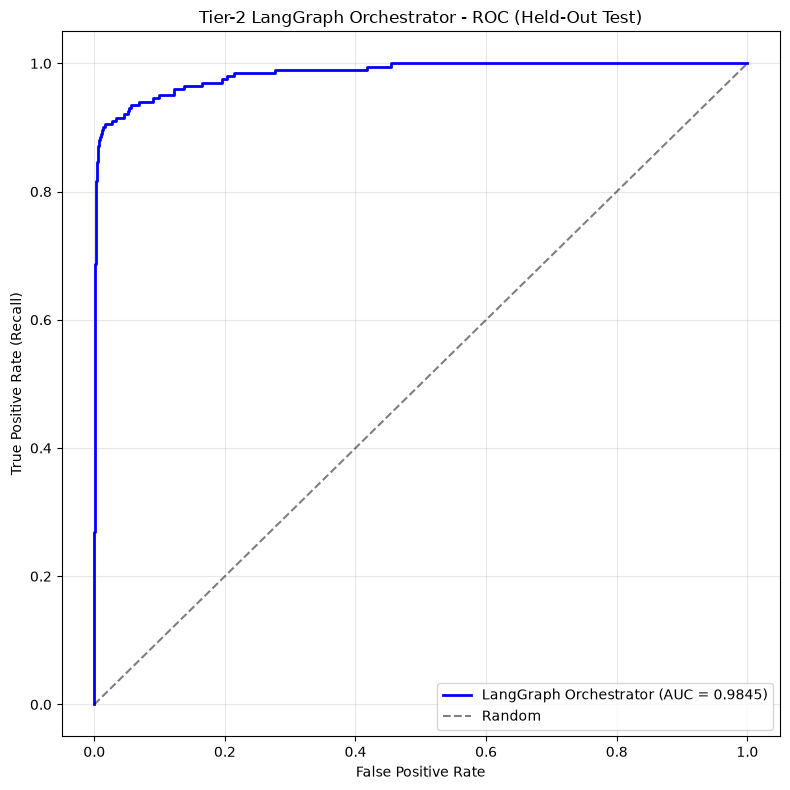

In [12]:
fpr_arr, tpr_arr, _ = roc_curve(y_true, df['risk_score'])
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 8))
plt.plot(fpr_arr, tpr_arr, 'b-', linewidth=2, label=f'LangGraph Orchestrator (AUC = {test_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Tier-2 LangGraph Orchestrator - ROC (Held-Out Test)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Comparison vs Week-1 Random Forest Binary (live, exact protocol)

In [13]:
# Exact Week-1 RF Binary protocol (week1_random_forest_binary.ipynb):
# features_clean.parquet + canonical 60/20/20 split + RF(200, balanced, 42) +
# Youden's-J threshold on validation + evaluate once on test.
from sklearn.ensemble import RandomForestClassifier

print('Replicating the existing Week-1 Binary RF baseline...')
X_w1 = pd.read_parquet(PROJECT_ROOT / 'data' / 'processed' / 'features_clean.parquet')
tr_u = np.load(PROJECT_ROOT / 'data' / 'user_splits' / 'train_users.npy')
va_u = np.load(PROJECT_ROOT / 'data' / 'user_splits' / 'val_users.npy')
te_u = np.load(PROJECT_ROOT / 'data' / 'user_splits' / 'test_users.npy')

tr_df = X_w1[X_w1['user'].isin(tr_u)]
va_df = X_w1[X_w1['user'].isin(va_u)]
te_df = X_w1[X_w1['user'].isin(te_u)]
feat = [c for c in X_w1.columns if c not in ('user', 'insider')]
Xtr, ytr = tr_df[feat], tr_df['insider'].astype(int).values
Xva, yva = va_df[feat], va_df['insider'].astype(int).values
Xte, yte = te_df[feat], te_df['insider'].astype(int).values

model_w1 = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)
model_w1.fit(Xtr, ytr)
p_va = model_w1.predict_proba(Xva)[:, 1]
best_j, best_t = -1.0, 0.5
for t in np.arange(0.05, 0.96, 0.05):
    preds = (p_va > t).astype(int)
    tn0, fp0, fn0, tp0 = confusion_matrix(yva, preds).ravel()
    fpr0 = fp0 / (fp0 + tn0) if (fp0 + tn0) > 0 else 0.0
    rec0 = recall_score(yva, preds, zero_division=0)
    j = rec0 - fpr0
    if j > best_j:
        best_j, best_t = j, t
p_te = model_w1.predict_proba(Xte)[:, 1]
y_pred_w1 = (p_te > best_t).astype(int)
w1 = {
    'Recall': recall_score(yte, y_pred_w1, zero_division=0),
    'FPR': 0.0,
    'Precision': precision_score(yte, y_pred_w1, zero_division=0),
    'F1': f1_score(yte, y_pred_w1, zero_division=0),
    'Accuracy': accuracy_score(yte, y_pred_w1),
    'ROC-AUC': roc_auc_score(yte, p_te),
}
tn_w1, fp_w1, fn_w1, tp_w1 = confusion_matrix(yte, y_pred_w1).ravel()
w1['FPR'] = fp_w1 / (fp_w1 + tn_w1) if (fp_w1 + tn_w1) > 0 else 0
print(f'Week-1 RF: thr={best_t:.2f} | Recall={w1["Recall"]:.4f} FPR={w1["FPR"]:.4f} '
      f'Precision={w1["Precision"]:.4f} F1={w1["F1"]:.4f} Accuracy={w1["Accuracy"]:.4f} ROC-AUC={w1["ROC-AUC"]:.4f}')

final_table = f"""
| Metric | Week-1 RF Binary | LangGraph Orchestrator |
| :--- | :--- | :--- |
| **Recall** | {w1['Recall']:.4f} | {test_recall:.4f} |
| **FPR** | {w1['FPR']:.4f} | {test_fpr:.4f} |
| **Precision** | {w1['Precision']:.4f} | {test_prec:.4f} |
| **F1** | {w1['F1']:.4f} | {test_f1:.4f} |
| **Accuracy** | {w1['Accuracy']:.4f} | {test_acc:.4f} |
| **ROC-AUC** | {w1['ROC-AUC']:.4f} | {test_auc:.4f} |
"""
display(Markdown('### Final comparison'))
display(Markdown(final_table))

Replicating the existing Week-1 Binary RF baseline...


Week-1 RF: thr=0.05 | Recall=0.6418 FPR=0.0089 Precision=0.1812 F1=0.2826 Accuracy=0.9900 ROC-AUC=0.9410


### Final comparison


| Metric | Week-1 RF Binary | LangGraph Orchestrator |
| :--- | :--- | :--- |
| **Recall** | 0.6418 | 0.9055 |
| **FPR** | 0.0089 | 0.0193 |
| **Precision** | 0.1812 | 0.1338 |
| **F1** | 0.2826 | 0.2332 |
| **Accuracy** | 0.9900 | 0.9804 |
| **ROC-AUC** | 0.9410 | 0.9845 |


## 9. Sample gate examples (sequential semantics)

In [14]:
print('\n' + '='*70)
print('  SAMPLE: HIGH-CONFIDENCE ESCALATIONS (http > HC_THRESHOLD)')
print('='*70)
hc = df[df['gate_triggered'] == 'high_confidence']
for _, row in hc.head(5).iterrows():
    print(f"\n  User {int(row['user'])} | Day {int(row['day'])} | Risk={row['risk_score']:.3f}")
    print(f"  Scores: HTTP={row['http_score']:.3f} File={row['file_device_score']:.3f} "
          f"Logon={row['logon_score']:.3f} Email={row['email_score']:.3f}")
    print(f"  corr_score={row['correlation_score']:.3f} > {CORRELATION_THRESHOLD:.2f}? {row['correlation_score'] > CORRELATION_THRESHOLD}")
    print(f"  Route: {row['gate_triggered']} (HC gate fired first)")

print('\n' + '='*70)
print('  SAMPLE: CORRELATION ESCALATIONS (http <= HC_THRESHOLD, corr > CORR_THRESHOLD)')
print('='*70)
corr = df[df['gate_triggered'] == 'correlation']
for _, row in corr.head(5).iterrows():
    print(f"\n  User {int(row['user'])} | Day {int(row['day'])} | Risk={row['risk_score']:.3f}")
    print(f"  Scores: HTTP={row['http_score']:.3f} File={row['file_device_score']:.3f} "
          f"Logon={row['logon_score']:.3f} Email={row['email_score']:.3f}")
    print(f"  http={row['http_score']:.3f} <= HC({HC_THRESHOLD:.2f})? {row['http_score'] <= HC_THRESHOLD} | "
          f"corr={row['correlation_score']:.3f} > {CORRELATION_THRESHOLD:.2f}? {row['correlation_score'] > CORRELATION_THRESHOLD}")
    print(f"  Route: {row['gate_triggered']} (HC did not fire; correlation fired)")


  SAMPLE: HIGH-CONFIDENCE ESCALATIONS (http > HC_THRESHOLD)

  User 9 | Day 365 | Risk=0.592
  Scores: HTTP=0.935 File=0.008 Logon=0.076 Email=0.215
  corr_score=0.592 > 0.22? True
  Route: high_confidence (HC gate fired first)

  User 11 | Day 280 | Risk=0.615
  Scores: HTTP=0.982 File=0.033 Logon=0.064 Email=0.128
  corr_score=0.615 > 0.22? True
  Route: high_confidence (HC gate fired first)

  User 11 | Day 287 | Risk=0.341
  Scores: HTTP=0.528 File=0.033 Logon=0.097 Email=0.077
  corr_score=0.341 > 0.22? True
  Route: high_confidence (HC gate fired first)

  User 11 | Day 486 | Risk=0.939
  Scores: HTTP=1.000 File=0.721 Logon=0.960 Email=0.992
  corr_score=0.939 > 0.22? True
  Route: high_confidence (HC gate fired first)

  User 11 | Day 487 | Risk=0.707
  Scores: HTTP=1.000 File=0.013 Logon=0.957 Email=0.090
  corr_score=0.707 > 0.22? True
  Route: high_confidence (HC gate fired first)

  SAMPLE: CORRELATION ESCALATIONS (http <= HC_THRESHOLD, corr > CORR_THRESHOLD)

  User 18 | D

## 10. Final configuration display (thresholds from validation)

In [15]:
print('=' * 60)
print('  FINAL TIER-2 LANGGRAPH ORCHESTRATOR CONFIGURATION')
print('=' * 60)
print('  HC policy:')
print("      ['http']")
print(f'  HC threshold:')
print(f'      {HC_THRESHOLD:.2f}   [SELECTED ON VALIDATION]')
print('  Correlation weights:')
print(f'      HTTP:        {W_HTTP:.2f}')
print(f'      File/Device: {W_FILE:.2f}')
print(f'      Logon:       {W_LOGON:.2f}')
print(f'      Email:       {W_EMAIL:.2f}')
print(f'  Correlation threshold:')
print(f'      {CORRELATION_THRESHOLD:.2f}   [SELECTED ON VALIDATION]')
print(f'  [FROZEN BEFORE TEST]')
print('  Validation:')
print(f'      Recall: {best_hc["Recall"]:.4f} (HC) / {best_corr["Recall"]:.4f} (Corr)')
print(f'      FPR:    {best_hc["FPR"]:.4f} (HC) / {best_corr["FPR"]:.4f} (Corr)')
print(f'      AUC:    {roc_auc_score(y_val, df_val["correlation_score"]):.4f}')
print('  Held-out Test:')
print(f'      Recall:    {test_recall:.4f}')
print(f'      FPR:       {test_fpr:.4f}')
print(f'      Precision: {test_prec:.4f}')
print(f'      F1:        {test_f1:.4f}')
print(f'      Accuracy:  {test_acc:.4f}')
print(f'      ROC-AUC:   {test_auc:.4f}')
print('=' * 60)

  FINAL TIER-2 LANGGRAPH ORCHESTRATOR CONFIGURATION
  HC policy:
      ['http']
  HC threshold:
      0.50   [SELECTED ON VALIDATION]
  Correlation weights:
      HTTP:        0.60
      File/Device: 0.20
      Logon:       0.10
      Email:       0.10
  Correlation threshold:
      0.22   [SELECTED ON VALIDATION]
  [FROZEN BEFORE TEST]
  Validation:
      Recall: 0.9372 (HC) / 0.9843 (Corr)
      FPR:    0.0062 (HC) / 0.0131 (Corr)
      AUC:    0.9960
  Held-out Test:
      Recall:    0.9055
      FPR:       0.0193
      Precision: 0.1338
      F1:        0.2332
      Accuracy:  0.9804
      ROC-AUC:   0.9845
